# SuperNeuroABM Tutorial 07: Writing a Step Function

A **step function** is the code that decides what one soma or one synapse does on a tick. The
built-in ones cover many models; to write your own you need to know what the framework expects
from yours and what it does not check for you.

This tutorial goes through one complete soma and one complete synapse, and every requirement they
have to meet:

1. how the numbers in a YAML config reach a kernel, what each parameter of the signature is and its
   shape, and what the helper functions do;
2. the soma, line by line;
3. the synapse, line by line;
4. what a channel is for, and how many you need;
5. two easy mistakes, run live: one that does not compile, one that gives no error at all;
6. testing a new kernel on one or two neurons before building a network;
7. a checklist.

Files used here, next to this notebook:

| file | what it is |
|---|---|
| `customized_configs/brunel_config.yaml` | the parameters of the soma and the synapse |
| `customized_step_functions/user_customized_brunel_soma.py` | section 2: a LIF soma with one exponential current per channel |
| `customized_step_functions/user_customized_brunel_synapse.py` | section 3: a synapse that delivers a weighted spike |

The soma and synapse come from a Brunel-style network, which is where their names come from. The
network itself is not part of this tutorial; only the two kernels are used here.

The complete reference for all of this, learning rules included, is `docs/CUSTOM_COMPONENTS.md`.

In [1]:
import importlib
import itertools
import sys
import tempfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import yaml

from superneuroabm.model import NeuromorphicModel

CONFIG = Path("customized_configs/brunel_config.yaml").resolve()
STEP_FUNC_DIR = Path("customized_step_functions").resolve()
sys.path.insert(0, str(STEP_FUNC_DIR))   # the tutorial-owned kernels are imported by module name
from user_customized_brunel_soma import user_customized_brunel_soma
from user_customized_brunel_synapse import user_customized_brunel_synapse

DT = 1e-4                                          # 0.1 ms ticks (the default is 1 ms)
SOMA_BREED = "user_customized_brunel_soma"         # the breed keys in the YAML
SYNAPSE_BREED = "user_customized_brunel_synapse"
SOMA_KERNEL = (user_customized_brunel_soma, STEP_FUNC_DIR / f"{SOMA_BREED}.py")
SYNAPSE_KERNEL = (user_customized_brunel_synapse, STEP_FUNC_DIR / f"{SYNAPSE_BREED}.py")
V, I_0, I_1 = 0, 3, 4                              # columns of a soma's history: its internal states, in YAML order

_scratch = tempfile.TemporaryDirectory()           # altered configs and kernels of sections 1 and 5
SCRATCH = Path(_scratch.name)
sys.path.insert(0, str(SCRATCH))
_counter = itertools.count()


def new_model(config=CONFIG, soma=SOMA_KERNEL, synapse=SYNAPSE_KERNEL, stepping="event"):
    "A model with a soma and a synapse kernel registered under this tutorial's breed names."
    model = NeuromorphicModel(user_config=config, synapse_stepping=stepping,
                              enable_internal_states_tracking=True)
    model.set_global_property_value("dt", DT)
    model.register_soma_type(name=SOMA_BREED, step_func=soma[0], step_func_path=soma[1])
    model.register_synapse_type(name=SYNAPSE_BREED, step_func=synapse[0], step_func_path=synapse[1],
                                event_capable=True)
    return model


def add_soma(model, **hyperparameters):
    return model.create_soma(breed=SOMA_BREED, config_name="brunel_lif_neuron",
                             overrides={"hyperparameters": hyperparameters})


def add_input(model, soma, config="brunel_excitatory_synapse", **hyperparameters):
    "An external input synapse on a soma (pre_soma_id=-1): it delivers the spikes injected into it."
    return model.create_synapse(breed=SYNAPSE_BREED, pre_soma_id=-1, post_soma_id=soma,
                                config_name=config, overrides={"hyperparameters": hyperparameters})


def history(model, soma):
    "Per-tick internal-state history of one soma as an array (ticks x columns)."
    return np.array(model.get_internal_states_history(soma), dtype=np.float64)

## 1. How a config reaches a kernel

A kernel is compiled for the GPU, and on the GPU there are no names, only numbers. The model reads
each YAML block in order and keeps its values (`_get_soma_properties` in `superneuroabm/model.py`):

```python
hp_vals = [float(v) for v in config["hyperparameters"].values()]
```

So a `hyperparameters` block becomes one row of numbers per agent, and `internal_states` becomes
another. The kernel reads those rows by position:

```text
customized_configs/brunel_config.yaml      user_customized_brunel_soma.py

  hyperparameters:
    C_m: 250.0e-12                         C_m = neuron_params[agent_index][0]
    tau_m: 0.020                           tau_m = neuron_params[agent_index][1]
    tau_syn_0: 0.0005                      tau_syn_ex = neuron_params[agent_index][2]
    tau_syn_1: 0.0005                      tau_syn_in = neuron_params[agent_index][3]
    ...
```

Two rules follow from this, and it helps to keep them apart.

**Position decides what the kernel reads.** `neuron_params[agent_index][2]` is the third key of the
block, whatever it is called. The name `tau_syn_ex` is a local variable in the kernel and does not
have to match the key `tau_syn_0`. If the key order and the index disagree, the kernel reads the
wrong number and nothing reports it.

**Names are for the Python side.** These are all the places a YAML key's name matters:

| where | what it requires |
|---|---|
| `overrides=`, `get_hyperparameters`, `set_hyperparameters` | the name is looked up and turned into a position, so any name works |
| creating a synapse | `weight` must be key 0 and `synaptic_delay` key 1, or `ValueError` |
| `setup()`, a soma config | if any hyperparameter starts with `tau_syn_`, then `tau_syn_0 ... tau_syn_{K-1}` and `I_syn_0 ... I_syn_{K-1}` must all exist, or `ValueError` (`K` is `NeuromorphicModel(synaptic_channels=K)`, default 2) |
| `setup()`, a synapse config | a key named `channel` must hold a value in `0 ... K-1`, or `ValueError` |

The checks in `setup()` look at names and values in the YAML. They cannot see which index a kernel
reads, so **passing them does not mean the config and the kernel agree**. The next cell prints the
rows the kernels will see, then tries four spellings of the soma's two time constants, with
`tau_syn_0` = 0.5 ms and `tau_syn_1` = 5 ms so that a mix-up shows. In each case one spike goes into
channel 0, and the kernel's decay is measured from the current it produces.

In [2]:
config = yaml.safe_load(CONFIG.read_text())
for what, block in (("soma", config["soma"][SOMA_BREED]["brunel_lif_neuron"]),
                    ("synapse", config["synapse"][SYNAPSE_BREED]["brunel_inhibitory_synapse"])):
    for row in ("hyperparameters", "internal_states"):
        print(f"{what} {row}:", {i: key for i, key in enumerate(block[row])})


def config_with(edit):
    "This tutorial's config with the soma's hyperparameters edited, as a temporary file."
    edited = yaml.safe_load(CONFIG.read_text())
    block = edited["soma"][SOMA_BREED]["brunel_lif_neuron"]
    block["hyperparameters"] = edit({**block["hyperparameters"], "tau_syn_1": 5e-3})
    path = SCRATCH / f"config_{next(_counter)}.yaml"
    path.write_text(yaml.safe_dump(edited, sort_keys=False))
    return path


def renamed(**names):
    return lambda hp: {names.get(key, key): value for key, value in hp.items()}


def tau_1_first(hp):
    keys = list(hp)
    i, j = keys.index("tau_syn_0"), keys.index("tau_syn_1")
    keys[i], keys[j] = keys[j], keys[i]
    return {key: hp[key] for key in keys}


CASES = {
    "A: tau_syn_0, tau_syn_1 (this tutorial)": renamed(),
    "B: tau_syn_ex, tau_syn_in": renamed(tau_syn_0="tau_syn_ex", tau_syn_1="tau_syn_in"),
    "C: tau_ex, tau_in": renamed(tau_syn_0="tau_ex", tau_syn_1="tau_in"),
    "D: tau_syn_1 written before tau_syn_0": tau_1_first,
}
print()
for name, edit in CASES.items():
    print(name)
    model = new_model(config=config_with(edit))
    soma = add_soma(model)
    syn = add_input(model, soma)
    try:
        model.setup()
    except ValueError as error:
        print(f"    setup(): ValueError: {error}")
        continue
    model.add_spike(syn, 10, 1.0)
    model.simulate(ticks=40)
    print("    setup(): passed")
    I = history(model, soma)[:, I_0]
    print(f"    the kernel decays channel 0 with tau = {-DT / np.log(I[12] / I[11]) * 1e3:.2f} ms", end="")
    hp = model.get_hyperparameters(soma)
    print(f"; get_hyperparameters says tau_syn_0 = {hp['tau_syn_0'] * 1e3:.2f} ms" if "tau_syn_0" in hp else "")

soma hyperparameters: {0: 'C_m', 1: 'tau_m', 2: 'tau_syn_0', 3: 'tau_syn_1', 4: 'V_th', 5: 'V_reset', 6: 'E_L', 7: 't_ref'}
soma internal_states: {0: 'V_m', 1: 'tcount', 2: 'tlast', 3: 'I_syn_0', 4: 'I_syn_1'}
synapse hyperparameters: {0: 'weight', 1: 'synaptic_delay', 2: 'channel'}
synapse internal_states: {0: 'unused'}

A: tau_syn_0, tau_syn_1 (this tutorial)


    setup(): passed
    the kernel decays channel 0 with tau = 0.50 ms; get_hyperparameters says tau_syn_0 = 0.50 ms
B: tau_syn_ex, tau_syn_in
    setup(): ValueError: soma config user_customized_brunel_soma/brunel_lif_neuron filters per inbox channel but lacks ['tau_syn_0', 'tau_syn_1'] for synaptic_channels=2
C: tau_ex, tau_in


    setup(): passed
    the kernel decays channel 0 with tau = 0.50 ms
D: tau_syn_1 written before tau_syn_0
    setup(): passed
    the kernel decays channel 0 with tau = 5.00 ms; get_hyperparameters says tau_syn_0 = 0.50 ms


- **A** is what this tutorial uses.
- **B** is refused, even though this kernel never looks at names. A key starting with `tau_syn_`
  tells `setup()` that the config follows the numbered convention, and then the numbered keys must
  exist. That is why the YAML says `tau_syn_0` while the kernel says `tau_syn_ex`.
- **C** skips the check, because no key starts with `tau_syn_`. The kernel works exactly as in A: it
  only reads positions. Tutorial 03's `tausyn` is a real example.
- **D** is the dangerous one. It passes the check because both names exist, and
  `get_hyperparameters` reports the value you wrote for that name. But the kernel's index 2 now holds
  the 5 ms value, so channel 0 decays ten times too slowly with no error anywhere.

The built-in helper `synaptic_current` (section 2) reads time constants by position too, so a config
for it needs the numbered names *and* the keys consecutive and in channel order.

### The signature

Every soma and synapse kernel takes the same 18 parameters in the same order, because the generated
code passes them by position. You can rename them (the soma calls slot 8 `neuron_params`, the
synapse `synapse_params`; it is the same tensor), except the last two, whose names the model looks
for. Many are unused by a given kernel, but all must be present.

`N` below is the rank's agent capacity, `T` the length of the history, `K` the number of channels.

| parameter | shape | what it is |
|---|---|---|
| `tick` | scalar | current tick |
| `agent_index` | scalar | this agent's row in the tensors below (a rank-local position, not its id) |
| `dt`, `I_bias` | scalars | global values |
| `agent_ids` | `(N,)` | the global id of each row |
| `breeds` | `(N,)` | the breed of each row |
| `locations` | a list per agent, of varying length | a synapse's `[pre_soma_index, post_soma_index]`; a soma's incoming synapses when its kernel uses them, else empty |
| `neuron_params` / `synapse_params` | `(N, widest hyperparameters block)` | the `hyperparameters` rows |
| `learning_params` | `(N, widest learning_hyperparameters block)` | a learning rule's parameters |
| `internal_states` | `(N, widest internal_states block)` | the `internal_states` rows, which the kernel updates |
| `learning_internal_states` | `(N, widest learning_internal_states block)` | a learning rule's state |
| `synapse_history` | `(N, 0)` | empty, kept so that the positions do not shift |
| `input_spikes_tensor` | `(N, 2)` | `[tick, value]` of the spike injected into each synapse |
| `output_spikes_tensor` | `(N, 2)` | each soma's spike, in slot `tick % 2` |
| `internal_states_buffer` | `(N, T, widest internal_states block)` | per-tick history |
| `learning_internal_states_buffer` | `(N, T, widest learning_internal_states block)` | a learning rule's per-tick history |
| `synaptic_input` | `(somas on this rank, K)` | the soma inbox (section 2); must come second to last, with this name |
| `synaptic_input_idx` | `(N,)` | each agent's row in the inbox, or -1; must come last, with this name |

If the last two are missing from a soma, it silently receives nothing; from a synapse, `setup()`
raises `ValueError`.

The next cell prints the real shapes from a small model: three somas and two synapses, 50 ticks.

In [3]:
model = new_model()
a, b, c = add_soma(model), add_soma(model), add_soma(model)
external = add_input(model, a)
recurrent = model.create_synapse(breed=SYNAPSE_BREED, pre_soma_id=a, post_soma_id=b,
                                 config_name="brunel_inhibitory_synapse")
model.setup()
model.add_spike(external, 5, 1.0)
model.simulate(ticks=50)

# _gpu_buffers is internal: fine for looking, not something to build on
buffers = model._gpu_buffers
index = model._agent_factory._property_name_2_index
kernel_name = {"breed": "breeds", "hyperparameters": "neuron_params / synapse_params",
               "learning_hyperparameters": "learning_params", "synapse_delay_reg": "synapse_history"}
names = {i: name for name, i in index.items()}
print(f"{'agent_ids':<34} {buffers.agent_ids_gpu.shape}")
for stat in buffers.property_alloc_stats:
    name = names[stat["prop_idx"]]
    print(f"{kernel_name.get(name, name):<34} {stat['shape']}")
print(f"{'synaptic_input':<34} {buffers.device_breed_locals[0].shape}")
print(f"{'synaptic_input_idx':<34} {buffers.device_breed_local_idxs[0].shape}")


def row(property_name, agent):
    return [float(f"{value:.4g}") for value in buffers.row_host(index[property_name], agent)]


print("\nhyperparameters of a soma:   ", row("hyperparameters", a))
print("hyperparameters of a synapse:", row("hyperparameters", external))
print("internal_states of a synapse:", row("internal_states", external))
print("input_spikes_tensor of the external synapse, after its spike at tick 5:", row("input_spikes_tensor", external))
print("locations of the two synapses:", {synapse: model.get_synapse_connectivity(synapse) for synapse in (external, recurrent)})

agent_ids                          (64,)
breeds                             (64,)
neuron_params / synapse_params     (64, 8)
learning_params                    (64, 1)
internal_states                    (64, 5)
learning_internal_states           (64, 0)
synapse_history                    (64, 0)
input_spikes_tensor                (64, 2)
output_spikes_tensor               (64, 2)
internal_states_buffer             (64, 50, 5)
learning_internal_states_buffer    (64, 50, 0)
synaptic_input                     (3, 2)
synaptic_input_idx                 (64,)

hyperparameters of a soma:    [2.5e-10, 0.02, 0.0005, 0.0005, 0.02, 0.0, 0.0, 0.002]
hyperparameters of a synapse: [4.97e-11, 0.0015, 0.0, nan, nan, nan, nan, nan]
internal_states of a synapse: [0.0, nan, nan, nan, nan]
input_spikes_tensor of the external synapse, after its spike at tick 5: [5.0, 1.0]
locations of the two synapses: {3: [-1, 0], 4: [0, 1]}


What this shows about the tensors:

- **All agents on a rank share them**, somas and synapses alike, so each is as wide as the widest
  block in the config: `hyperparameters` is 8 wide because of the soma. A synapse uses the first 3
  entries of its row, and the rest is NaN. A kernel that reads past its own block gets NaN with no
  error.
- **The first dimension is a capacity, not the number of agents**: `max(64, agents on this rank)`, ghosts
  included, so 64 here for 5 agents. The extra rows hold no agent. Only use the row given by
  `agent_index` or by `locations`, and do not use a tensor's length as the number of agents.
- **`T` is the history length**: the number of ticks when tracking is on, 1 when it is off. That is
  why the write index is `tick % len(internal_states_buffer[agent_index])`.
- **`synaptic_input` is the exception to the first rule.** It has rows only for somas, which is why
  `synaptic_input_idx` exists (section 2).
- **Values are stored as float32**, including ones used as integers, hence `int(...)` around a channel.
- **`locations` of a synapse is `[pre, post]`**, with -1 for an external input. A soma has a
  list, its incoming synapses, only when its kernel uses `locations`; this soma does not, so it
  has none.

### What a kernel is

Your function is not called as Python. `setup()` reads its source, rewrites it and fuses it into one
generated kernel (`step_func_code_<hash>.py`, written to the working directory, worth reading when
debugging), and that kernel **compiles at the first `simulate()`**. A `setup()` that passes therefore
says nothing about whether your kernel compiles.

Inside a kernel you can use scalar math, `if`, `for i in range(...)`, `while`, `cp.exp` and similar,
indexing into the tensors, and calls to other `@jit.rawkernel(device="cuda")` functions such as the
helpers used below. You cannot use Python objects, lists, dicts, NumPy, `print` or exceptions.

### The helper functions

A spike goes from one soma to the next in three hops, and each hop has a helper. A soma firing on tick
`t` reaches the next soma on tick `t + 2`:

```text
tick t       soma A    writes its spike           output_spikes_tensor[agent_index][t % 2] = spike
tick t + 1   synapse   reads that spike           get_soma_spike(...)
tick t + 1   synapse   adds a value to the inbox  deliver_synaptic_current(...)
tick t + 2   soma B    reads the inbox            read_synaptic_input(...) or synaptic_current(...)
```

| helper | called by | what it does |
|---|---|---|
| `get_soma_spike` | synapse | the spike this synapse has to deliver now: its pre soma's output of the previous tick, or the spike injected for this tick if the pre slot is -1; 0.0 if there is none |
| `deliver_synaptic_current` | synapse | adds a value into one channel of a soma's inbox |
| `read_synaptic_input` | soma | what was delivered into one channel of this soma's inbox last tick |
| `synaptic_current` | soma | the standard filter in one call: decays every channel, adds what arrived, stores it, returns the sum |

`get_soma_spike` is in `superneuroabm/step_functions/synapse/util.py`, the others in
`superneuroabm/step_functions/synaptic_input.py`. They are small kernels compiled into yours, and worth
reading. They exist so that your kernel does not have to deal with where a soma's inbox row is, with the
write buffer behind the inbox, or with the two sources a spike can come from.

## 2. The soma, line by line

A soma kernel runs once per soma on every tick. This is all of
`customized_step_functions/user_customized_brunel_soma.py`, in order.

**Read the parameters and the state**, by position. `agent_index` is this soma's row. These are
local copies: a change to `V` is lost unless the kernel writes it back at the end.

```python
C_m = neuron_params[agent_index][0]
...
V = internal_states[agent_index][0]
```

**Read the inbox.** A synapse never touches a soma's state. It adds a value to the soma's **inbox**.
Two parameters make up the inbox:

- `synaptic_input` is the table: one row per soma on this rank (ghost somas included), one column per
  channel. A row holds the total from all of that soma's synapses, not one value per synapse.
- `synaptic_input_idx` is the lookup: one integer per agent, the agent's row in the table, or -1 if it
  has none. Synapses have none, and `agent_index` counts them too, which is why a soma's row cannot be
  worked out from its `agent_index`.

What is delivered on tick `t` is what the soma reads on tick `t + 1`; the framework then clears it.

```python
I_syn_exc_in = read_synaptic_input(agent_index, synaptic_input, synaptic_input_idx, 0)
I_syn_inh_in = read_synaptic_input(agent_index, synaptic_input, synaptic_input_idx, 1)
```

A soma's row is `synaptic_input_idx[agent_index]`, so always go through a helper instead of indexing
the table yourself. There are two (`superneuroabm/step_functions/synaptic_input.py`):

| helper | gives you | use it when |
|---|---|---|
| `read_synaptic_input(...)` | the raw total delivered into one channel | the soma filters its input itself, like this one |
| `synaptic_current(...)` | decays every channel by `1 - dt / tau_syn_c`, adds what arrived, stores it, returns the sum | the standard filter is what you want; the built-in somas use it |

The next cell shows both arrays: three somas, two synapses onto soma b and one onto soma c, each given
one spike at tick 10.

In [4]:
def inbox_after(ticks):
    "The inbox and its lookup at the end of a run of this many ticks."
    model = new_model()
    a, b, c = add_soma(model), add_soma(model), add_soma(model)
    synapses = add_input(model, b), add_input(model, b), add_input(model, c, "brunel_inhibitory_synapse")
    model.setup()
    for synapse in synapses:
        model.add_spike(synapse, 10, 1.0)
    model.simulate(ticks=ticks)
    return model._gpu_buffers.device_breed_locals[0].get(), model._gpu_buffers.device_breed_local_idxs[0].get()


inbox, lookup = inbox_after(11)
print("agents, by agent_index:           a  b  c  syn syn syn")
print("synaptic_input_idx[:6]:          ", lookup[:6].tolist())
print("synaptic_input shape:            ", inbox.shape)
for ticks in (10, 11, 12):
    inbox, _ = inbox_after(ticks)
    print(f"synaptic_input at the end of tick {ticks - 1:>2} (pA): {np.round(inbox.astype(float) * 1e12, 1).tolist()}")

agents, by agent_index:           a  b  c  syn syn syn
synaptic_input_idx[:6]:           [0, 1, 2, -1, -1, -1]
synaptic_input shape:             (3, 2)


synaptic_input at the end of tick  9 (pA): [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
synaptic_input at the end of tick 10 (pA): [[0.0, 0.0], [99.4, 0.0], [0.0, -248.5]]


synaptic_input at the end of tick 11 (pA): [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]


Soma b's row holds 99.4 pA, the two synapses' 49.7 pA added together, and soma c's holds -248.5 pA in
channel 1, as that synapse's config says. Each value is there for one tick only, so a soma that needs it
longer has to keep it in its own state, which is what the next step does. The rows match `agent_index`
here only because the somas come first in this small model. With several soma types they do not: agents
are grouped by type, so a soma at `agent_index` 6 can have inbox row 2.

**Filter the current.** Decay each channel with its own time constant and add what arrived. Each
channel's current is state, so it is kept between ticks.

```python
decay_exc = cp.exp(-dt / tau_syn_ex)
decay_inh = cp.exp(-dt / tau_syn_in)
I_syn_exc = I_syn_exc * decay_exc + I_syn_exc_in
I_syn_inh = I_syn_inh * decay_inh + I_syn_inh_in
I_syn = I_syn_exc + I_syn_inh
```

**Integrate the membrane, unless refractory.** Everything in this file is in SI units, `dt` included.
A kernel has no unit system; yours is whatever your config and `dt` are consistently in.

```python
time_since_spike = (dt * tcount) - tlast
in_refractory = time_since_spike < t_ref
if not in_refractory:
    dV = (-(V - E_L) / tau_m + (I_syn + I_bias) / C_m) * dt
    V += dV
```

**Decide the spike and reset.**

```python
spike = 1.0 if (V >= V_th and not in_refractory) else 0.0
if spike > 0.5:
    V = V_reset
    tlast = dt * tcount
```

**Write the state back**, in the same positions it was read from. `tcount` is not computed from
`tick` here: this soma keeps its own count, which starts at 0 and goes up by one per tick.

```python
internal_states[agent_index][0] = V
internal_states[agent_index][1] += 1.0
internal_states[agent_index][2] = tlast
internal_states[agent_index][3] = I_syn_exc
internal_states[agent_index][4] = I_syn_inh
```

**Write the spike. This line is required.** Synapses read it, and in event stepping it is what wakes
them. A soma that forgets it never reaches its network, with no error. The slot is `tick % 2`: a
two-slot ring, and readers take the previous tick's slot.

```python
output_spikes_tensor[agent_index][t_current % 2] = spike
```

**Write the history**, which is what `get_internal_states_history` returns. The index must be
`tick % len(...)`: with tracking off the row has length 1, and the modulo keeps the write in range.
(The `if len(...) > 0` around this block in the file is harmless and not needed; the built-ins write
unconditionally.)

```python
buffer_idx = t_current % len(internal_states_buffer[agent_index])
internal_states_buffer[agent_index][buffer_idx][0] = V
...
```

**Register it** before `setup()`. The `name` must equal the breed key in the YAML, and the file and
function names must be unique across all components, because `setup()` generates
`from <file stem> import *`.

```python
model.register_soma_type(
    name="user_customized_brunel_soma",
    step_func=user_customized_brunel_soma,
    step_func_path=STEP_FUNC_DIR / "user_customized_brunel_soma.py",
)
```

The first test of a kernel should be small enough to check by hand. The next cell gives this soma one
spike and writes the same model in NumPy next to it.

largest relative difference, kernel vs NumPy: current 2.5e-08, membrane 2.2e-07
membrane peak 0.1000 mV at tick 29


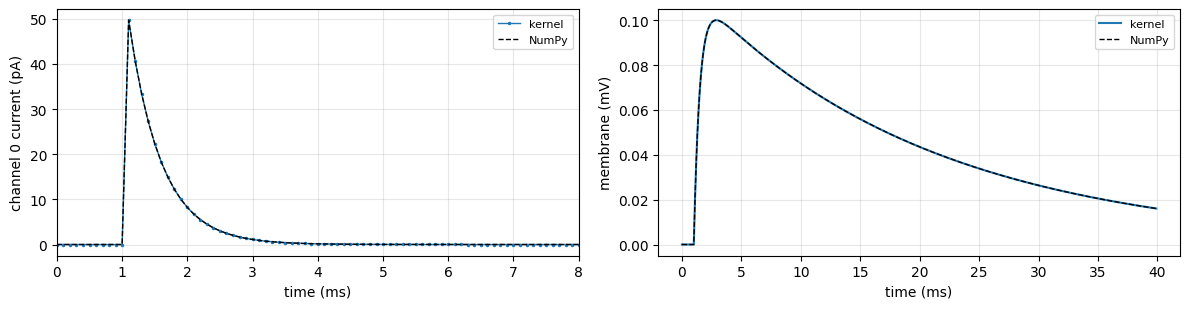

In [5]:
TICKS = 400
model = new_model()
soma = add_soma(model)
syn = add_input(model, soma)
model.setup()
model.add_spike(syn, 10, 1.0)      # delivered on tick 10, so the soma reads it on tick 11
model.simulate(ticks=TICKS)
h = history(model, soma)
hp = model.get_hyperparameters(soma)
weight = model.get_hyperparameters(syn)["weight"]

# The same model in NumPy
I_np, V_np = np.zeros(TICKS), np.zeros(TICKS)
for t in range(1, TICKS):
    I_np[t] = I_np[t - 1] * np.exp(-DT / hp["tau_syn_0"]) + (weight if t == 11 else 0.0)
    V_np[t] = V_np[t - 1] + (-(V_np[t - 1] - hp["E_L"]) / hp["tau_m"] + I_np[t] / hp["C_m"]) * DT

print(f"largest relative difference, kernel vs NumPy: current {np.abs(h[:, I_0] - I_np).max() / I_np.max():.1e}, "
      f"membrane {np.abs(h[:, V] - V_np).max() / V_np.max():.1e}")
print(f"membrane peak {h[:, V].max() * 1e3:.4f} mV at tick {h[:, V].argmax()}")

t_ms = np.arange(TICKS) * DT * 1e3
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(t_ms, h[:, I_0] * 1e12, marker=".", ms=3, lw=1, label="kernel")
axes[0].plot(t_ms, I_np * 1e12, "--", color="k", lw=1, label="NumPy")
axes[0].set_xlim(0, 8)
axes[0].set_ylabel("channel 0 current (pA)")
axes[1].plot(t_ms, h[:, V] * 1e3, lw=1.5, label="kernel")
axes[1].plot(t_ms, V_np * 1e3, "--", color="k", lw=1, label="NumPy")
axes[1].set_ylabel("membrane (mV)")
for ax in axes:
    ax.set_xlabel("time (ms)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. The synapse, line by line

In event stepping a synapse kernel runs only when it has a spike to deliver: on the tick after its
presynaptic soma fired, or on a tick an input was injected into it. This is all of
`customized_step_functions/user_customized_brunel_synapse.py`.

**Read the parameters**, by position. Slots 0 and 1 of every synapse are reserved for `weight` and
`synaptic_delay`, so a custom synapse's own parameters start at index 2. **`synaptic_delay` must be
in the YAML, but no kernel reads it.** The time from a spike to its arrival is fixed, as measured
below.

```python
weight = synapse_params[agent_index][0]
channel = int(synapse_params[agent_index][2])
```

**Find the two ends.** `locations[agent_index]` is `[pre_soma_index, post_soma_index]`, already local
indices. The framework rewrites this code, so stick to this pattern: one alias of the row, indexed.

```python
_nbrs = locations[agent_index]
pre_soma_index = int(_nbrs[0])
post_soma_index = -1
if len(_nbrs) > 1:
    post_soma_index = int(_nbrs[1])
```

**Read the spike.** `get_soma_spike` covers both sources: the pre soma's output of the previous tick,
or, when the pre slot is `-1`, the spike injected into this synapse for this tick.

```python
spike = get_soma_spike(tick, agent_index, dt, I_bias, agent_ids, pre_soma_index,
                       t_current, input_spikes_tensor, output_spikes_tensor)
if spike == 0.0:
    return
```

Delivery into the inbox is a push, but that is only the last hop: the synapse still has to read the spike
from its source. In event stepping, being woken says that there is something to do, not what it is:

- a spike has two possible sources, stored in different places;
- it has a value: an injected spike can be larger than 1 (`model.add_spike(synapse, tick, 3.0)`), and the
  delivered value is `spike * weight`;
- in clocked stepping every synapse runs every tick, so the `spike == 0.0` return is what makes an idle
  one do nothing, and the same kernel has to work in both steppings;
- on several ranks, the spike slot is what crosses between ranks: a pre soma on another rank is a ghost
  row in `output_spikes_tensor`, read in the same way.

**Deliver.** This adds the value to the post soma's inbox row in slot `channel`. It is the only way a
synapse affects a soma, and it is safe with many synapses delivering to one soma on one tick.

```python
synaptic_current = spike * weight
deliver_synaptic_current(synaptic_input, synaptic_input_idx, post_soma_index, channel, synaptic_current)
```

There is no sign logic: **an inhibitory synapse is a synapse with a negative weight.**

**Register it**, with `event_capable=True` as the promise that the kernel keeps no per-tick state, so
skipping it on ticks without a spike changes nothing. Event stepping refuses a synapse type without
it. Tutorial 05 explains what this promise requires.

```python
model.register_synapse_type(
    name="user_customized_brunel_synapse",
    step_func=user_customized_brunel_synapse,
    step_func_path=STEP_FUNC_DIR / "user_customized_brunel_synapse.py",
    event_capable=True,
)
```

This kernel is the built-in `delivery_synapse` minus its `scale` parameter. A model that needs nothing
more should use the built-in; it is copied here because it is the smallest complete example, and the
starting point for a synapse that computes something else.

The next cell checks three things: that each synapse reaches the channel its config names, how long a
spike takes to reach the next soma, and that event and clocked stepping agree.

In [6]:
def two_inputs(soma_hp=None, inh_hp=None, synapse=SYNAPSE_KERNEL, inh_tick=400):
    "One soma, an excitatory spike at tick 100 and an inhibitory one at inh_tick: its history."
    model = new_model(synapse=synapse)
    soma = add_soma(model, **(soma_hp or {}))
    exc = add_input(model, soma)
    inh = add_input(model, soma, "brunel_inhibitory_synapse", **(inh_hp or {}))
    model.setup()
    model.add_spike(exc, 100, 1.0)
    model.add_spike(inh, inh_tick, 1.0)
    model.simulate(ticks=1200)
    return history(model, soma)


h = two_inputs()
print(f"excitatory spike, one tick later: I_syn_0 = {h[101, I_0] * 1e12:7.1f} pA, I_syn_1 = {h[101, I_1] * 1e12:7.1f} pA")
print(f"inhibitory spike, one tick later: I_syn_0 = {h[401, I_0] * 1e12:7.1f} pA, I_syn_1 = {h[401, I_1] * 1e12:7.1f} pA")


def soma_to_soma(stepping):
    "A pre soma fired by one strong input at tick 10, connected to a post soma."
    model = new_model(stepping=stepping)
    pre, post = add_soma(model), add_soma(model)
    kick = add_input(model, pre, weight=1e-7)     # strong enough to fire on one spike
    model.create_synapse(breed=SYNAPSE_BREED, pre_soma_id=pre, post_soma_id=post,
                         config_name="brunel_excitatory_synapse")
    model.setup()
    model.add_spike(kick, 10, 1.0)
    model.simulate(ticks=80)
    return model.get_spike_times(pre), history(model, post)


pre_spikes, post_event = soma_to_soma("event")
_, post_clocked = soma_to_soma("clocked")
arrival = int(np.argmax(post_event[:, I_0] != 0))
print(f"pre soma fired at tick {pre_spikes[0]}; the post soma's current first moved at tick {arrival}: "
      f"{arrival - pre_spikes[0]} ticks = {(arrival - pre_spikes[0]) * DT * 1e3:.1f} ms")
print("the YAML's synaptic_delay is 1.5 ms and is not read")
print("post soma identical in event and clocked stepping:", np.array_equal(post_event, post_clocked))

excitatory spike, one tick later: I_syn_0 =    49.7 pA, I_syn_1 =     0.0 pA
inhibitory spike, one tick later: I_syn_0 =     0.0 pA, I_syn_1 =  -248.5 pA


pre soma fired at tick 11; the post soma's current first moved at tick 13: 2 ticks = 0.2 ms
the YAML's synaptic_delay is 1.5 ms and is not read
post soma identical in event and clocked stepping: True


## 4. What a channel is for

A natural guess is that a model with excitatory and inhibitory neurons needs two channels, one for
each. It does not.

> **A channel is one decay time constant on the soma.** The sign of an input comes from the
> synapse's weight.

So a soma needs **one channel per distinct time constant among its inputs**, not one per kind of
synapse. This config gives both channels 0.5 ms, so two channels decay identically and adding them
gives the same current as one. Two only change anything when excitation and inhibition should decay
at different rates. The cell below runs three cases with one excitatory spike and, 0.3 ms later while
its current is still flowing, one inhibitory spike:

- two channels with the same time constant (this config);
- the same, with the inhibitory synapse sent into channel 0 (`overrides` on its `channel`);
- two channels with different time constants: `tau_syn_1` = 5 ms.

inhibition in channel 0 still pulls the current down: I_syn_0 at tick 104 = -221.2 pA
largest membrane difference, two channels vs one: 7.28e-09 mV (membrane swing 0.45 mV)


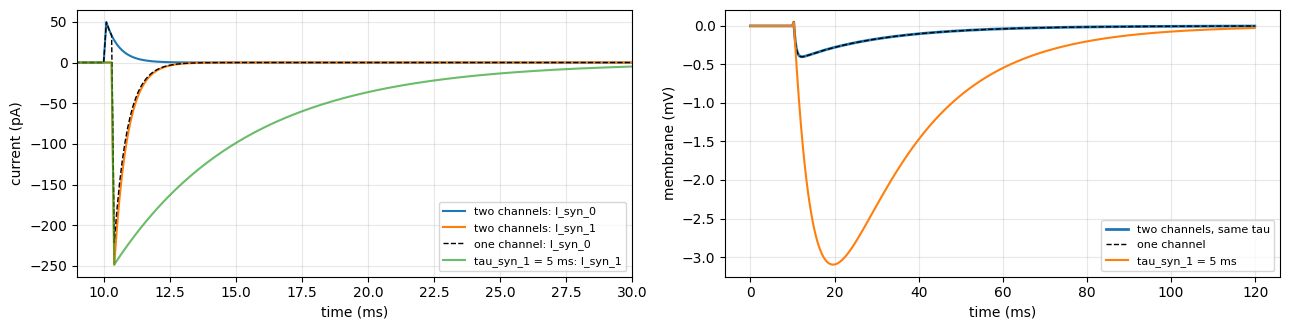

In [7]:
two_channels = two_inputs(inh_tick=103)
one_channel = two_inputs(inh_tick=103, inh_hp={"channel": 0})
different_tau = two_inputs(inh_tick=103, soma_hp={"tau_syn_1": 5e-3})

print(f"inhibition in channel 0 still pulls the current down: I_syn_0 at tick 104 = {one_channel[104, I_0] * 1e12:.1f} pA")
print(f"largest membrane difference, two channels vs one: {np.abs(two_channels[:, V] - one_channel[:, V]).max() * 1e3:.2e} mV "
      f"(membrane swing {np.ptp(two_channels[:, V]) * 1e3:.2f} mV)")

t_ms = np.arange(1200) * DT * 1e3
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].plot(t_ms, two_channels[:, I_0] * 1e12, lw=1.5, label="two channels: I_syn_0")
axes[0].plot(t_ms, two_channels[:, I_1] * 1e12, lw=1.5, label="two channels: I_syn_1")
axes[0].plot(t_ms, one_channel[:, I_0] * 1e12, "--", color="k", lw=1, label="one channel: I_syn_0")
axes[0].plot(t_ms, different_tau[:, I_1] * 1e12, lw=1.5, alpha=0.7, label="tau_syn_1 = 5 ms: I_syn_1")
axes[0].set_xlim(9, 30)
axes[0].set_ylabel("current (pA)")
axes[1].plot(t_ms, two_channels[:, V] * 1e3, lw=2, label="two channels, same tau")
axes[1].plot(t_ms, one_channel[:, V] * 1e3, "--", color="k", lw=1, label="one channel")
axes[1].plot(t_ms, different_tau[:, V] * 1e3, lw=1.5, label="tau_syn_1 = 5 ms")
axes[1].set_ylabel("membrane (mV)")
for ax in axes:
    ax.set_xlabel("time (ms)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The first two cases have the same membrane potential to float rounding (the dashed line lies on the
solid one), and the inhibitory spike pulls the current negative in whichever channel it lands. The third is the case that does need two channels:
inhibition lasts longer than excitation.

To really use one channel with this soma you would change the kernel to read only slot 0, drop
`tau_syn_1` and `I_syn_1` from the config, and pass `NeuromorphicModel(synaptic_channels=1)`. This
tutorial keeps two because the file is then ready for different time constants. Tutorial 06 covers
channels in depth.

## 5. Two easy mistakes

Both of these are one-line changes to the kernels above, and both came up when these kernels were
first written. The helper below makes a temporary copy of a kernel file with one piece of text
replaced.

### A kernel that does not compile

The natural first guess at reading the inbox is to index it directly, with a guard for the range:

```python
I_syn_exc_in = synaptic_input[agent_index * 2 + 0] if agent_index * 2 + 0 < len(synaptic_input) else 0.0
```

This assumes the inbox is a flat array with two entries per soma. It is a table:
`synaptic_input[i]` is a whole row, not a number, and a soma's row is
`synaptic_input_idx[agent_index]`. Here is what running it looks like.

In [8]:
def kernel_variant(kernel, tag, old, new):
    "A copy of a kernel file with one piece of text replaced, as a new module and function."
    name = f"{kernel}_{tag}"
    source = (STEP_FUNC_DIR / f"{kernel}.py").read_text()
    assert source.count(old) == 1, old
    path = SCRATCH / f"{name}.py"
    path.write_text(source.replace(old, new).replace(f"def {kernel}(", f"def {name}("))
    return getattr(importlib.import_module(name), name), path


flat_inbox = kernel_variant(
    SOMA_BREED, "flat_inbox",
    "I_syn_exc_in = read_synaptic_input(agent_index, synaptic_input, synaptic_input_idx, 0)",
    "I_syn_exc_in = synaptic_input[agent_index * 2 + 0] if agent_index * 2 + 0 < len(synaptic_input) else 0.0",
)
model = new_model(soma=flat_inbox)
add_soma(model)
model.setup()
print("setup(): passed")
try:
    model.simulate(ticks=1)
except Exception as error:
    lines = str(error).splitlines()
    print(f"simulate(): {type(error).__name__}, message {lines[0]!r}")
    print("the message is followed by the kernel's whole source; the first line marked with '>' is:")
    print(next(line for line in lines if line.startswith(">"))[:110])

setup(): passed
simulate(): AssertionError, message ''
the message is followed by the kernel's whole source; the first line marked with '>' is:
>     I_syn_exc_in = synaptic_input[agent_index * 2 + 0] if agent_index * 2 + 0 < len(synaptic_input) else 0.0


Three things to remember from this:

- **`setup()` passes.** The kernel compiles at the first `simulate()`, so that is where a compile error
  appears.
- **The message can be empty.** The compiler prints the whole generated kernel and marks the line it
  stopped at with `>`. Look for the first `>`, which is in your kernel; a later one marks where the
  generated code calls your kernel, and the traceback is inside `cupyx`.
- **Leave errors uncaught while developing a kernel.** A script that wraps its run in `try/except`
  and prints the exception exits with status 0, and the failure is easy to miss among thousands of
  lines of printed source.

### A kernel that runs and is wrong

Slot 1 of a synapse is reserved for `synaptic_delay`, but a first draft of this synapse documented its
parameters as `[weight, channel]` and read the channel from index 1:

```python
channel = int(synapse_params[agent_index][1])     # the YAML's index 1 is synaptic_delay = 0.0015
```

`int(0.0015)` is 0, so every synapse delivers into channel 0. No check catches this: the YAML's
`channel: 1` is a valid value, so the range check passes, and `get_hyperparameters` reports `channel`
as 1. The next cell runs the correct kernel and this one, with equal time constants and with
different ones.

In [9]:
wrong_channel = kernel_variant(
    SYNAPSE_BREED, "wrong_channel",
    "channel = int(synapse_params[agent_index][2])",
    "channel = int(synapse_params[agent_index][1])",
)
for label, soma_hp in (("same time constants", None), ("tau_syn_1 = 5 ms", {"tau_syn_1": 5e-3})):
    right = two_inputs(soma_hp=soma_hp)
    wrong = two_inputs(soma_hp=soma_hp, synapse=wrong_channel)
    print(label)
    print(f"    I_syn_1 after the inhibitory spike: correct {right[401, I_1] * 1e12:7.1f} pA, wrong index {wrong[401, I_1] * 1e12:7.1f} pA")
    print(f"    lowest membrane potential:          correct {right[:, V].min() * 1e3:7.4f} mV, wrong index {wrong[:, V].min() * 1e3:7.4f} mV")
    print(f"    largest membrane difference: {np.abs(right[:, V] - wrong[:, V]).max() * 1e3:.2e} mV")

same time constants
    I_syn_1 after the inhibitory spike: correct  -248.5 pA, wrong index     0.0 pA
    lowest membrane potential:          correct -0.4773 mV, wrong index -0.4773 mV
    largest membrane difference: 0.00e+00 mV


tau_syn_1 = 5 ms
    I_syn_1 after the inhibitory spike: correct  -248.5 pA, wrong index     0.0 pA
    lowest membrane potential:          correct -3.1522 mV, wrong index -0.4773 mV
    largest membrane difference: 2.82e+00 mV


With equal time constants the wrong index does not even change the membrane, because both channels
decay alike: the bug is invisible in every result you would normally look at, until someone gives the
channels different time constants. The way to catch it is to look at one channel directly, as section
3 does, before relying on it.

## 6. Test a new kernel before building a network

A network that does nothing and a network that does the wrong thing both look like a successful run.
On one or two neurons, each thing that can go wrong is a number you can read. Sections 2 and 3 already
checked that the kernel matches a hand-written model, that each synapse uses its channel, how long a
spike takes to arrive, and that both steppings agree. Two more belong here.

**How big is one spike?** Measure it. Units that look right can still be far off: `0.0355e-12` A was
the excitatory weight in a first draft of this config, and it looks like a plausible small current.
The cell below reads the membrane's peak response to one spike, then scales the weight to the size
wanted, here 0.1 mV.

**Does the refractory period work?** Fire the soma as fast as it can go and read the intervals.

In [10]:
def psp_peak_mv(weight):
    model = new_model()
    soma = add_soma(model)
    syn = add_input(model, soma, weight=weight)
    model.setup()
    model.add_spike(syn, 10, 1.0)
    model.simulate(ticks=600)
    return history(model, soma)[:, V].max() * 1e3


draft_weight = 0.0355e-12
draft_peak = psp_peak_mv(draft_weight)
print(f"weight {draft_weight * 1e12:.4f} pA: peak {draft_peak:.6f} mV, against a threshold of 20 mV")
print(f"weight for a 0.1 mV peak: {0.1 / draft_peak * draft_weight * 1e12:.1f} pA")
print(f"weight {49.7:.1f} pA (the config's value): peak {psp_peak_mv(49.7e-12):.4f} mV")

# The refractory period: a spike strong enough to fire the soma, on every tick
model = new_model()
soma = add_soma(model)
kick = add_input(model, soma, weight=1e-7)
model.setup()
input_ticks = np.arange(10, 400)
model.add_spikes(np.full(input_ticks.size, kick), input_ticks)
model.simulate(ticks=420)
spikes = np.array(model.get_spike_times(soma))
intervals, counts = np.unique(np.diff(spikes), return_counts=True)
print(f"\n{spikes.size} spikes; intervals in ticks: {dict(zip(intervals.tolist(), counts.tolist()))} "
      f"(t_ref / dt = {model.get_hyperparameters(soma)['t_ref'] / DT:.0f})")
h = history(model, soma)
print(f"membrane held at reset during the first refractory period: {np.all(h[spikes[0]:spikes[1], V] == 0.0)}")

weight 0.0355 pA: peak 0.000071 mV, against a threshold of 20 mV
weight for a 0.1 mV peak: 49.7 pA
weight 49.7 pA (the config's value): peak 0.1000 mV



20 spikes; intervals in ticks: {20: 8, 21: 11} (t_ref / dt = 20)
membrane held at reset during the first refractory period: True


The draft weight moves the membrane by 0.00007 mV, about 1,400 times less than the 0.1 mV wanted and
far from a 20 mV threshold. A network built on it would run to the end without an error and without a
spike. One line of output here finds what would otherwise look like a problem with the network.

The refractory intervals are 20 or 21 ticks, not always 20. Twenty ticks after a spike,
`dt * tcount - tlast` equals `t_ref` exactly on paper, so float rounding decides which side of the
`<` it falls on. A model that needs the exact count should count refractory ticks in its state
instead of comparing times.

## 7. A checklist for your own step function

**Writing the kernel**

- Start from a kernel close to what you want: `superneuroabm/step_functions/` for the built-ins,
  `customized_step_functions/` for the tutorials' own.
- Keep all 18 parameters in order, with `synaptic_input, synaptic_input_idx` last.
- A soma reads its input through `read_synaptic_input` or `synaptic_current`, never by indexing the
  inbox.
- A soma writes `output_spikes_tensor[agent_index][tick % 2]` on every tick, and history at
  `tick % len(internal_states_buffer[agent_index])`.
- A soma writes every changed state back to `internal_states`.
- A synapse gets its spike from `get_soma_spike` and acts only through `deliver_synaptic_current`.
- For event stepping, a synapse keeps no per-tick state (tutorial 05).

**Writing the config**

- Write the docstring's parameter list and the YAML together. **Key order is index order**, for
  `hyperparameters` and `internal_states` separately.
- A synapse's first two keys are `weight`, `synaptic_delay`, and its own start at index 2.
  `synaptic_delay` is not read by anything.
- Keys starting with `tau_syn_` must be the numbered ones, with matching `I_syn_<c>` states.
- One channel per distinct time constant. The sign of an input comes from its weight.
- Pick one set of units for every value and for `dt`.

**Registering**

- `name` equals the YAML's breed key, before `setup()`.
- File and function names are unique across all components.
- `event_capable=True` on a synapse only if it keeps no per-tick state.

**Testing, smallest first**

- One soma, one spike: compare with the model written in NumPy, and read the size of the response.
- Each channel on its own: is the value where the config says it should be?
- Two somas: does a spike arrive, and when?
- Event against clocked stepping.
- Only then a network, checking that it is not silent.

**When something goes wrong**

| symptom | where to look |
|---|---|
| A compile error at the first `simulate()`, possibly with an empty message | the line marked `>` in the printed source |
| `ValueError` at `setup()` about `tau_syn` or `I_syn` | the numbered key names (section 1) |
| `ValueError: 'weight' must be key #0` | synapse key order |
| Runs, but a value is wrong, with no error | key order against kernel indices: print `{i: key}` as in section 1 |
| Runs, nothing fires | is input injected? how big is one spike (section 6)? |
| The post soma receives nothing | the soma's `output_spikes_tensor` write, the synapse's `deliver_synaptic_current`, the soma's inbox read |